# Análisis de Planeación de la Demanda

## Exploración inicial del dataset

In [175]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar dataset
df = pd.read_csv("dataset_planeacion_demanda.csv")

# Dimensiones
print("Dimensiones:", df.shape)

# Primeros registros
display(df.head())

# Tipos de datos
df.info()

# Valores nulos
print("\nValores nulos:")
print(df.isnull().sum())

# Registros duplicados
print("\nDuplicados:", df.duplicated().sum())

# Estadísticas descriptivas
display(df.describe())

# Número de productos
print("\nProductos:", df["sku"].nunique())

# Periodo analizado
print("Desde:", df["fecha"].min())
print("Hasta:", df["fecha"].max())

Dimensiones: (300, 8)


,fecha,sku,producto,categoria,unidades_vendidas,precio_unitario,promocion,inventario_final
0,2021-01-01,SKU001,Arroz 1 kg,Abarrotes,1083,28.22,0,520
1,2021-01-01,SKU002,Aceite 1 L,Abarrotes,867,41.86,0,228
2,2021-01-01,SKU003,Detergente 1 kg,Limpieza,734,55.04,0,0
3,2021-01-01,SKU004,Papel higiénico 4 pzas,Higiene,531,48.28,0,129
4,2021-01-01,SKU005,Leche 1 L,Lácteos,1197,24.85,0,411


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fecha              300 non-null    object 
 1   sku                300 non-null    object 
 2   producto           300 non-null    object 
 3   categoria          300 non-null    object 
 4   unidades_vendidas  300 non-null    int64  
 5   precio_unitario    300 non-null    float64
 6   promocion          300 non-null    int64  
 7   inventario_final   300 non-null    int64  
dtypes: float64(1), int64(3), object(4)
memory usage: 18.9+ KB

Valores nulos:
fecha                0
sku                  0
producto             0
categoria            0
unidades_vendidas    0
precio_unitario      0
promocion            0
inventario_final     0
dtype: int64

Duplicados: 0


,unidades_vendidas,precio_unitario,promocion,inventario_final
count,300.000000,300.000000,300.000000,300.000000
mean,1089.596667,41.597933,0.186667,270.680000
std,467.753974,12.180390,0.390295,254.180967
min,401.000000,24.560000,0.000000,0.000000
25%,711.000000,28.532500,0.000000,66.500000
50%,992.500000,44.095000,0.000000,225.000000
75%,1473.500000,51.860000,0.000000,411.250000
max,2537.000000,61.650000,1.000000,1190.000000



Productos: 5
Desde: 2021-01-01
Hasta: 2025-12-01


In [176]:
# Análisis exploratorio de la demanda
# Convertir fecha
df["fecha"] = pd.to_datetime(df["fecha"])

# Ordenar información
df = df.sort_values(["sku", "fecha"])

# Demanda mensual total
demanda_mensual = (
    df.groupby("fecha")["unidades_vendidas"]
    .sum()
    .reset_index()
)

display(demanda_mensual.head())

,fecha,unidades_vendidas
0,2021-01-01,4412
1,2021-02-01,5092
2,2021-03-01,4921
3,2021-04-01,4633
4,2021-05-01,5005


## Visualizar comportamiento histórico

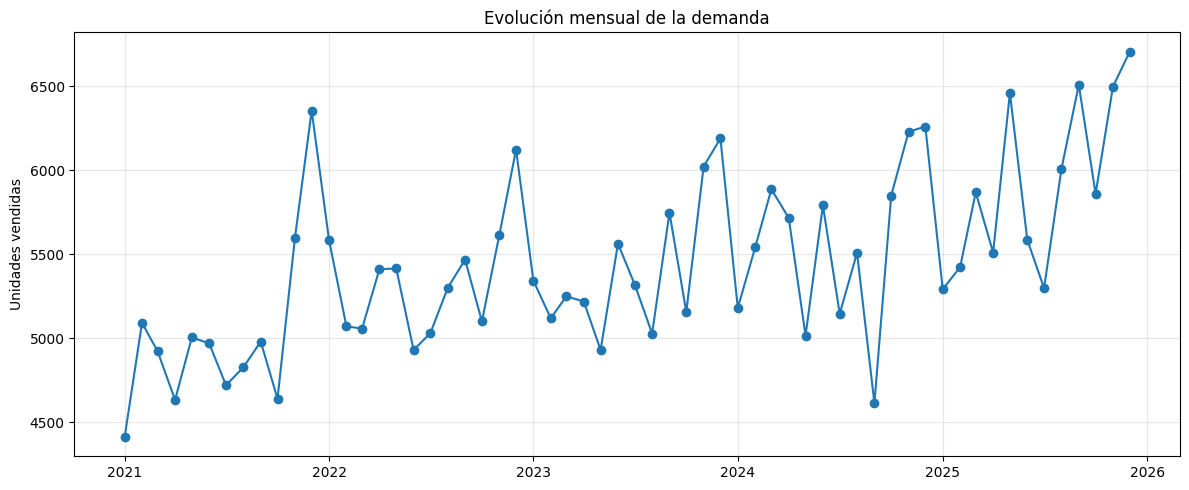

In [177]:
plt.figure(figsize=(12, 5))

plt.plot(
    demanda_mensual["fecha"],
    demanda_mensual["unidades_vendidas"],
    marker="o"
)

plt.title("Evolución mensual de la demanda")
plt.xlabel("")
plt.ylabel("Unidades vendidas")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Comparar productos

In [ ]:
demanda_productos = df.pivot(
    index="fecha",
    columns="producto",
    values="unidades_vendidas"
)

demanda_productos.plot(figsize=(13, 9))

plt.title("Evolución de la demanda por producto")
plt.xlabel("")
plt.ylabel("Unidades vendidas")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Identificar tendencias y estacionalidad

In [ ]:
# Tendencia anual
df["anio"] = df["fecha"].dt.year

anual = df.groupby(
    ["sku", "producto", "anio"]
)["unidades_vendidas"].mean().reset_index()

tabla = anual.pivot(
    index=["sku", "producto"],
    columns="anio",
    values="unidades_vendidas"
)

tabla["variacion_%"] = (
    tabla[2025] / tabla[2021] - 1
) * 100

display(tabla.round(2))

,anio,2021,2022,2023,2024,2025,variacion_%
sku,producto,,,,,,
SKU001,Arroz 1 kg,1346.83,1428.50,1482.67,1579.25,1669.67,23.97
SKU002,Aceite 1 L,912.75,1010.58,969.67,975.00,977.50,7.09
SKU003,Detergente 1 kg,717.00,694.75,733.75,737.75,755.92,5.43
SKU004,Papel higiénico 4 pzas,574.92,551.75,570.17,597.58,650.67,13.18
SKU005,Leche 1 L,1460.75,1656.17,1650.67,1671.58,1864.08,27.61


## Descomposición de series temporales

Utilizaremos el método clásico de descomposición aditiva:

\[
Y_t=T_t+S_t+R_t
\]

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

resultados = []

for sku, grupo in df.groupby("sku"):

    serie = (
        grupo.set_index("fecha")["unidades_vendidas"]
        .asfreq("MS")
    )

    descomp = seasonal_decompose(
        serie,
        model="additive",
        period=12,
        extrapolate_trend="freq"
    )

    resultados.append({
        "SKU": sku,
        "Tendencia_inicial": descomp.trend.iloc[0],
        "Tendencia_final": descomp.trend.iloc[-1],
        "Estacionalidad_max": descomp.seasonal.max(),
        "Estacionalidad_min": descomp.seasonal.min(),
        "Desviacion_residuos": descomp.resid.std()
    })

display(pd.DataFrame(resultados).round(2))

,SKU,Tendencia_inicial,Tendencia_final,Estacionalidad_max,Estacionalidad_min,Desviacion_residuos
0,SKU001,1310.15,1641.66,420.96,-302.19,176.38
1,SKU002,905.14,990.04,115.65,-199.99,98.63
2,SKU003,709.84,766.22,105.94,-116.10,68.00
3,SKU004,594.97,671.64,196.38,-106.50,51.33
4,SKU005,1383.90,1959.31,235.48,-213.87,146.88


In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

resultados = []

for sku, grupo in df.groupby("sku"):

    serie = (
        grupo.set_index("fecha")["unidades_vendidas"]
        .asfreq("MS")
    )

    descomp = seasonal_decompose(
        serie,
        model="additive",
        period=12,
        extrapolate_trend="freq"
    )

    resultados.append({
        "SKU": sku,
        "Tendencia_inicial": descomp.trend.iloc[0],
        "Tendencia_final": descomp.trend.iloc[-1],
        "Estacionalidad_max": descomp.seasonal.max(),
        "Estacionalidad_min": descomp.seasonal.min(),
        "Desviacion_residuos": descomp.resid.std()
    })

display(pd.DataFrame(resultados).round(2))

,SKU,Tendencia_inicial,Tendencia_final,Estacionalidad_max,Estacionalidad_min,Desviacion_residuos
0,SKU001,1310.15,1641.66,420.96,-302.19,176.38
1,SKU002,905.14,990.04,115.65,-199.99,98.63
2,SKU003,709.84,766.22,105.94,-116.10,68.00
3,SKU004,594.97,671.64,196.38,-106.50,51.33
4,SKU005,1383.90,1959.31,235.48,-213.87,146.88


## Pronóstico

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

resultados = []
pronosticos = []

for sku, grupo in df.groupby("sku"):

    serie = (
        grupo.set_index("fecha")["unidades_vendidas"]
        .asfreq("MS")
    )

    train = serie.iloc[:-12]
    test = serie.iloc[-12:]

    # Modelo Naive estacional
    pred_naive = train.iloc[-12:].values

    # Modelo Holt-Winters
    modelo = ExponentialSmoothing(
        train,
        trend="add",
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)

    pred_hw = modelo.forecast(12)

    for nombre, pred in [
        ("Naive estacional", pred_naive),
        ("Holt-Winters", pred_hw)
    ]:

        resultados.append({
            "SKU": sku,
            "Modelo": nombre,
            "MAE": mean_absolute_error(test, pred),
            "RMSE": np.sqrt(mean_squared_error(test, pred)),
            "MAPE": np.mean(np.abs((test.values - pred) / test.values)) * 100,
            "BIAS": np.mean(pred - test.values)
        })

    pronosticos.append(pd.DataFrame({
        "fecha": test.index,
        "sku": sku,
        "real": test.values,
        "pronostico": pred_hw.values
    }))

metricas = pd.DataFrame(resultados)

display(metricas.round(2))

# Guardar pronósticos
pronosticos_df = pd.concat(pronosticos)
pronosticos_df.to_csv(
    "pronosticos_2025.csv",
    index=False
)

,SKU,Modelo,MAE,RMSE,MAPE,BIAS
0,SKU001,Naive estacional,290.92,373.20,16.57,-90.42
1,SKU001,Holt-Winters,131.56,162.82,7.66,-22.50
2,SKU002,Naive estacional,111.83,136.90,11.43,-2.50
3,SKU002,Holt-Winters,77.30,99.74,8.67,25.96
4,SKU003,Naive estacional,98.17,138.01,12.71,-18.17
5,SKU003,Holt-Winters,54.34,90.43,7.16,-9.79
6,SKU004,Naive estacional,78.08,120.26,11.15,-53.08
7,SKU004,Holt-Winters,75.59,110.39,10.65,-55.46
8,SKU005,Naive estacional,264.00,354.37,12.83,-192.50
9,SKU005,Holt-Winters,234.82,329.88,11.42,-201.48


## Proyección de los próximos 12 meses

In [ ]:
pronosticos_2026 = []

for sku, grupo in df.groupby("sku"):

    serie = (
        grupo.set_index("fecha")["unidades_vendidas"]
        .asfreq("MS")
    )

    modelo = ExponentialSmoothing(
        serie,
        trend="add",
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)

    forecast = modelo.forecast(12)

    temporal = pd.DataFrame({
        "fecha": forecast.index,
        "sku": sku,
        "demanda_pronosticada": forecast.values
    })

    pronosticos_2026.append(temporal)

pronosticos_2026 = pd.concat(
    pronosticos_2026,
    ignore_index=True
)

pronosticos_2026["demanda_pronosticada"] = (
    pronosticos_2026["demanda_pronosticada"].clip(lower=0).round()
)

display(pronosticos_2026.head(15))

# Exportar resultados
pronosticos_2026.to_csv(
    "pronosticos_2026.csv",
    index=False
)

,fecha,sku,demanda_pronosticada
0,2026-01-01,SKU001,1672.0
1,2026-02-01,SKU001,1676.0
2,2026-03-01,SKU001,1665.0
3,2026-04-01,SKU001,1429.0
4,2026-05-01,SKU001,1498.0
5,2026-06-01,SKU001,1513.0
6,2026-07-01,SKU001,1631.0
7,2026-08-01,SKU001,1687.0
8,2026-09-01,SKU001,1906.0
9,2026-10-01,SKU001,1930.0


## Calcular stock de seguridad y punto de reorden

Utilizaremos la desviación estándar de los errores de pronóstico obtenidos durante 2025.


In [ ]:
# Error de pronóstico
errores = pronosticos_df.copy()

errores["error"] = errores["real"] - errores["pronostico"]

# Desviación de errores por producto
sigma_error = errores.groupby("sku")["error"].std()

# Supuestos
z = 1.645
lead_time = 15 / 30
periodo_revision = 30 / 30

# Demanda promedio mensual pronosticada
demanda_media = (
    pronosticos_2026.groupby("sku")
    ["demanda_pronosticada"].mean()
)

# Tabla de inventarios
inventarios = pd.DataFrame({
    "demanda_mensual": demanda_media,
    "sigma_error": sigma_error
})

# Stock de seguridad
inventarios["stock_seguridad"] = (
    z * inventarios["sigma_error"] * np.sqrt(lead_time)
)

# Demanda durante lead time
inventarios["demanda_lead_time"] = (
    inventarios["demanda_mensual"] * lead_time
)

# Punto de reorden
inventarios["punto_reorden"] = (
    inventarios["demanda_lead_time"] +
    inventarios["stock_seguridad"]
)

# Stock objetivo: lead time + periodo de revisión
inventarios["stock_objetivo"] = (
    inventarios["demanda_mensual"] *
    (lead_time + periodo_revision) +
    inventarios["stock_seguridad"]
)

display(inventarios.round(2))

,demanda_mensual,sigma_error,stock_seguridad,demanda_lead_time,punto_reorden,stock_objetivo
sku,,,,,,
SKU001,1740.58,168.43,195.91,870.29,1066.20,2806.79
SKU002,997.17,100.59,117.00,498.58,615.59,1612.75
SKU003,764.00,93.90,109.22,382.00,491.22,1255.22
SKU004,689.67,99.69,115.96,344.83,460.79,1150.46
SKU005,1907.33,272.81,317.33,953.67,1271.00,3178.33


## Clasificación ABC de productos

El objetivo es identificar qué productos representan mayor valor económico para la empresa.

In [ ]:
abc = abc.sort_values(
    "valor_anual",
    ascending=False
).reset_index(drop=True)

abc["participacion"] = (
    abc["valor_anual"] / abc["valor_anual"].sum()
)

abc["acumulado"] = abc["participacion"].cumsum()

abc["clasificacion"] = np.select(
    [
        abc["acumulado"] <= 0.80,
        abc["acumulado"] <= 0.95
    ],
    ["A", "B"],
    default="C"
)

display(abc[[
    "sku", "producto", "valor_anual",
    "participacion", "acumulado", "clasificacion"
]].round(3))

,sku,producto,valor_anual,participacion,acumulado,clasificacion
0,SKU001,Arroz 1 kg,651047.79,0.230,0.230,A
1,SKU005,Leche 1 L,627131.20,0.221,0.451,A
2,SKU003,Detergente 1 kg,562273.44,0.198,0.649,A
3,SKU002,Aceite 1 L,551393.28,0.194,0.843,B
4,SKU004,Papel higiénico 4 pzas,444172.92,0.157,1.000,C


## Integrar los resultados


Vamos a reunir los resultados de pronósticos, inventarios y clasificación ABC en una sola tabla.

In [ ]:
reporte = (
    inventarios.reset_index()
    .merge(abc, on="sku")
)

columnas = [
    "sku",
    "producto",
    "clasificacion",
    "demanda_anual",
    "valor_anual",
    "stock_seguridad",
    "punto_reorden",
    "stock_objetivo"
]

reporte = reporte[columnas]

display(reporte.round(2))

reporte.to_csv(
    "reporte_planeacion_demanda.csv",
    index=False
)

,sku,producto,clasificacion,demanda_anual,valor_anual,stock_seguridad,punto_reorden,stock_objetivo
0,SKU001,Arroz 1 kg,A,20887.0,651047.79,195.91,1066.20,2806.79
1,SKU002,Aceite 1 L,B,11966.0,551393.28,117.00,615.59,1612.75
2,SKU003,Detergente 1 kg,A,9168.0,562273.44,109.22,491.22,1255.22
3,SKU004,Papel higiénico 4 pzas,C,8276.0,444172.92,115.96,460.79,1150.46
4,SKU005,Leche 1 L,A,22888.0,627131.20,317.33,1271.00,3178.33


## Recomendación Final de compra

In [ ]:
# Inventario inicial simulado
stock_actual = (
    df.sort_values("fecha")
    .groupby("sku")
    .tail(1)[["sku", "inventario_final"]]
    .rename(columns={"inventario_final": "inventario_disponible"})
)

# Integrar información
plan_compras = reporte.merge(stock_actual, on="sku")

# Posición de inventario
plan_compras["posicion_inventario"] = (
    plan_compras["inventario_disponible"]
)

# Recomendación de compra
plan_compras["cantidad_compra"] = np.maximum(
    0,
    np.ceil(
        plan_compras["stock_objetivo"] -
        plan_compras["posicion_inventario"]
    )
)

display(plan_compras[[
    "sku", "producto", "clasificacion",
    "inventario_disponible", "punto_reorden",
    "stock_objetivo", "cantidad_compra"
]].round(0).reset_index(drop=True))

plan_compras.to_csv(
    "plan_compras.csv",
    index=False
)

,sku,producto,clasificacion,inventario_disponible,punto_reorden,stock_objetivo,cantidad_compra
0,SKU001,Arroz 1 kg,A,784,1066.0,2807.0,2023.0
1,SKU002,Aceite 1 L,B,0,616.0,1613.0,1613.0
2,SKU003,Detergente 1 kg,A,412,491.0,1255.0,844.0
3,SKU004,Papel higiénico 4 pzas,C,120,461.0,1150.0,1031.0
4,SKU005,Leche 1 L,A,453,1271.0,3178.0,2726.0


Nota: es un escenario ilustrativo, no una política de inventarios validada. En producción se incorporarían pedidos en tránsito, restricciones de proveedores y costos.  